By : Rajdeep Ghosh, PhD Research Scholar, CSE-IITKGP

Reach out at [Linkedin](https://www.linkedin.com/in/ghoshrajdeep2000/) / Email: ghoshrajdeep2000@gmail.com

## **Introduction and Motivation**




Recap:
- Transformer -> Attention, Self Attention, Encoder-Decoder models
- Embeddings -> learned parameters --- All subsequent operations operate on these vectors
- Positional Information

Roadmap

- Text $\rightarrow$ Tokenizer $\rightarrow$ Token IDs
- Token IDs $\rightarrow$ Embedding Layer $\rightarrow$ Vectors
- Vectors + Positional Embeddings $\rightarrow$ Final Input for Model

Today we'll do today—tokenization, token IDs, embeddings, positional encodings—exists to produce the matrix that enters the first Transformer layer

If tokenization or embeddings are poorly designed, no amount of attention can fix it.---Transformers are powerful, but they only see what tokenization and embeddings allow them to see.

Tokenization is at the heart of much weirdness of LLMs. Do not brush it off.

- Why can't LLM spell words? **Tokenization**.
- Why can't LLM do super simple string processing tasks like reversing a string? **Tokenization**.
- Why is LLM worse at non-English languages (e.g. Japanese)? **Tokenization**.
- Why is LLM bad at simple arithmetic? **Tokenization**.
- Why did GPT-2 have more than necessary trouble coding in Python? **Tokenization**.
- Why did my LLM abruptly halt when it sees the string "<|endoftext|>"? **Tokenization**.
- What is this weird warning I get about a "trailing whitespace"? **Tokenization**.
- Why the LLM break if I ask it about "SolidGoldMagikarp"? **Tokenization**.
- Why should I prefer to use YAML over JSON with LLMs? **Tokenization**.
- Why is LLM not actually end-to-end language modeling? **Tokenization**.
- What is the real root of suffering? **Tokenization**.

---

Good tokenization web app: [https://tiktokenizer.vercel.app](https://tiktokenizer.vercel.app)



# <b>A) From user input to model layers</b>

### Data Preparation and Sampling to get Input Data "ready" for the *LLM*

Packages that are being used in this notebook:

In [ ]:
from importlib.metadata import version

print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

torch version: 2.11.0+cu128
tiktoken version: 0.14.0


<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/01.webp?timestamp=1" width="1000px">

### **0. Understanding Word Embeddings**

- There are many forms of embeddings; our focus is on text embeddings

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/02.webp" width="800px">

- LLMs work with embeddings in high-dimensional spaces (i.e., thousands of dimensions)
- Since we can't visualize such high-dimensional spaces (we humans think in 1, 2, or 3 dimensions), the figure below illustrates a 2-dimensional embedding space

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/03.webp" width="700px">

### **1. Tokenizing Text**

- In this section, we tokenize text, which means breaking text into smaller units, such as individual words and punctuation characters

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/04.webp" width="700px">

- Load raw text we want to work with
- [The Verdict by Edith Wharton](https://en.wikisource.org/wiki/The_Verdict) is a public domain short story

In [ ]:
import os                     # Used to check whether the file already exists locally
import urllib.request         # Used to download the file from a remote URL

if not os.path.exists("the-verdict.txt"):
    url = ("https://raw.githubusercontent.com/rasbt/"
           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
           "the-verdict.txt")
    file_path = "the-verdict.txt"
    urllib.request.urlretrieve(url, file_path)  # Download and save the file locally


- (If you encounter an `ssl.SSLCertVerificationError` when executing the previous code cell, it might be due to using an outdated Python version; you can find [more information here on GitHub](https://github.com/rasbt/LLMs-from-scratch/pull/403))

In [ ]:
# Open the text file explicitly using UTF-8 to avoid encoding issues and Read the entire file content into a single string
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of character:", len(raw_text))
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


- The goal is to tokenize and embed this text for an LLM
- Let's develop a simple tokenizer based on some simple sample text that we can then later apply to the text above
- The following regular expression will split on whitespaces

In [ ]:
# Import the regular expression module
import re

text = "Hello, world. This, 9 is a test."
result = re.split(r'(\s)', text)           # Split on whitespace while *preserving* whitespace tokens via capturing group

print(result)


['Hello,', ' ', 'world.', ' ', 'This,', ' ', '9', ' ', 'is', ' ', 'a', ' ', 'test.']


- We don't only want to split on whitespaces but also commas and periods, so let's modify the regular expression to do that as well

- Resource to learn more regex: https://www.w3schools.com/python/python_regex.asp


In [ ]:
result = re.split(r'([,.]|\s)', text)  # Split on commas, periods, or whitespace while keeping commas and periods as separate tokens

print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', '9', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


- As we can see, this creates empty strings, let's remove them

In [ ]:
# Strip whitespace from each item and then filter out any empty strings.
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', '9', 'is', 'a', 'test', '.']


- This looks pretty good, but let's also handle other types of punctuation, such as periods, question marks, and so on

In [ ]:
text = "Hello, world. Is this-- a test?"

result = re.split(r'([,.:;?_!"()\']|--|\s)', text)  # Split while retaining punctuation and the '--' sequence as separate tokens
result = [item.strip() for item in result if item.strip()]  # Clean up whitespace and discard empty split results

print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


- This is pretty good, and we are now ready to apply this tokenization to the raw text

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/05.webp" width="500px">

In [ ]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)  # Split text while preserving punctuation and separators as tokens
preprocessed = [item.strip() for item in preprocessed if item.strip()]  # Remove empty tokens + normalize whitespace
print(preprocessed[:30])


['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


- Let's calculate the total number of tokens

In [ ]:
print(len(preprocessed))

4690


### **2. Converting Tokens Into Token IDs**

- Next, we convert the text tokens into token IDs that we can process via embedding layers later

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/06.webp" width="800px">

- From these tokens, we can now build a vocabulary that consists of all the unique tokens

In [ ]:
all_words = sorted(set(preprocessed)) # Extract unique tokens from the preprocessed list and sort them lexicographically
vocab_size = len(all_words) #number of the tokens

print(vocab_size)


1130


In [ ]:
vocab = {token:integer for integer,token in enumerate(all_words)}

- Below are the first 50 entries in this vocabulary:

In [ ]:
for i, item in enumerate(vocab.items()): # printing first 50 tokens and their ids
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


- Below, we illustrate the tokenization of a short sample text using a small vocabulary:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/07.webp?123" width="800px">

- Putting it now all together into a tokenizer class

In [ ]:
# Define a simple tokenizer class that maps strings ↔ integers
class SimpleTokenizerV1:

    def __init__(self, vocab):
        self.str_to_int = vocab  # vocab: dictionary mapping token (string) → unique integer ID
        self.int_to_str = {i: s for s, i in vocab.items()}  # Create the inverse mapping: integer ID → token string. Required for decoding

    def encode(self, text):  # Split the input text into tokens using a regex and return the corresponding integer ID

        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)',text)  # punctuation, double-dash, or whitespace
        preprocessed = [item.strip() for item in preprocessed if item.strip()]# Remove empty strings and strip whitespace from each token
        ids = [self.str_to_int[s] for s in preprocessed] # Convert each token into its corresponding integer ID
        return ids # Return the list of token IDs

    def decode(self, ids): # Convert each integer ID back to its corresponding token string
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text) # Remove unnecessary spaces before punctuation marks
        return text # Return the reconstructed text


- The `encode` function turns text into token IDs
- The `decode` function turns token IDs back into text

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/08.webp?123" width="700px">

- We can use the tokenizer to encode (that is, tokenize) texts into integers
- These integers can then be embedded (later) as input of/for the LLM

In [ ]:
tokenizer = SimpleTokenizerV1(vocab)  # Initialize the tokenizer with a predefined vocabulary (token → ID mapping)

text = """"It's the last he painted, you know,"
           Mrs. Gisburn said with pardonable pride."""  # Input text

ids = tokenizer.encode(text)  # Convert the input text into a list of integer token IDs using regex-based splitting

print(ids)


[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


- We can decode the integers back into text

In [ ]:
tokenizer.decode(ids) # convert the list of integer to the actual text

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

In [ ]:
tokenizer.decode(tokenizer.encode(text))

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

### **3. Adding Special Context Tokens**

- It's useful to add some "special" tokens for unknown words and to denote the end of a text

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/09.webp?123" width="800px">

- Some tokenizers use special tokens to help the LLM with additional context
- Some of these special tokens are
  - `[BOS]` (beginning of sequence) marks the beginning of text
  - `[EOS]` (end of sequence) marks where the text ends (this is usually used to concatenate multiple unrelated texts, e.g., two different Wikipedia articles or two different books, and so on)
  - `[PAD]` (padding) if we train LLMs with a batch size greater than 1 (we may include multiple texts with different lengths; with the padding token we pad the shorter texts to the longest length so that all texts have an equal length)
- `[UNK]` to represent words that are not included in the vocabulary

- Note that GPT-2 does not need any of these tokens mentioned above but only uses an `<|endoftext|>` token to reduce complexity
- The `<|endoftext|>` is analogous to the `[EOS]` token mentioned above
- GPT also uses the `<|endoftext|>` for padding (since we typically use a mask when training on batched inputs, we would not attend padded tokens anyways, so it does not matter what these tokens are)
- GPT-2 does not use an `<UNK>` token for out-of-vocabulary words; instead, GPT-2 uses a byte-pair encoding (BPE) tokenizer, which breaks down words into subword units which we will discuss in a later section



- We use the `<|endoftext|>` tokens between two independent sources of text:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/10.webp" width="800px">

- Let's see what happens if we tokenize the following text:

In [ ]:
tokenizer = SimpleTokenizerV1(vocab)

text = "Hello, do you like tea. Is this-- a test?"

tokenizer.encode(text)

KeyError: 'Hello'

- The above produces an error because the word "Hello" is not contained in the vocabulary
- To deal with such cases, we can add special tokens like `"<|unk|>"` to the vocabulary to represent unknown words
- Since we are already extending the vocabulary, let's add another token called `"<|endoftext|>"` which is used in GPT-2 training to denote the end of a text (and it's also used between concatenated text, like if our training datasets consists of multiple articles, books, etc.)

In [ ]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"]) # adding two new tokens to our list of tokens

vocab = {token:integer for integer,token in enumerate(all_tokens)}

In [ ]:
len(vocab.items())

1132

In [ ]:
for i, item in enumerate(list(vocab.items())[-5:]): #note the new tokens added at the end
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


- We also need to adjust the tokenizer accordingly so that it knows when and how to use the new `<unk>` token

In [ ]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = { i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed] # Replace unseen tokens with an explicit unknown token

        ids = [self.str_to_int[s] for s in preprocessed] # Map tokens (including <|unk|>) to integer IDs
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

Let's try to tokenize text with the modified tokenizer:

In [ ]:
tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

text = " <|endoftext|> ".join((text1, text2))

print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [ ]:
tokenizer.encode(text)

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]

In [ ]:
tokenizer.decode(tokenizer.encode(text))

'<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.'

### **4. BytePair Encoding (BPE)**

- GPT-2 used BytePair encoding (BPE) as its tokenizer
- It allows the model to break down words that aren't in its predefined vocabulary into smaller subword units or even individual characters, enabling it to handle out-of-vocabulary words
- For instance, if GPT-2's vocabulary doesn't have the word "unfamiliarword," it might tokenize it as ["unfam", "iliar", "word"] or some other subword breakdown, depending on its trained BPE merges
- The original BPE tokenizer can be found here: [https://github.com/openai/gpt-2/blob/master/src/encoder.py](https://github.com/openai/gpt-2/blob/master/src/encoder.py)
- Here, we are using the BPE tokenizer from OpenAI's open-source [tiktoken](https://github.com/openai/tiktoken) library, which implements its core algorithms in Rust to improve computational performance
- See the [Byte Pair Encoding (BPE) Tokenizer From Scratch](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch02/05_bpe-from-scratch/bpe-from-scratch.ipynb) notebook if you are interested in learning how the GPT-2 tokenizer can be implemented and trained from scratch.

In [ ]:
# pip install tiktoken

In [ ]:
import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [ ]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


- BPE tokenizers break down unknown words into subwords and individual characters:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/11.webp" width="700px">

**The Key Idea**

Frequent character pairs get merged into a single token. Repeat until you hit your vocab size.







**How It Works (Step by Step)**

1. Start with characters

Take your corpus. Split every word into characters, with a special end-of-word marker (`</w>`):

```
low    → l o w </w>
lower  → l o w e r </w>
newest → n e w e s t </w>
widest → w i d e s t </w>
```

Your initial vocabulary is just all unique characters.

---

2. Count all adjacent pairs

Count how often each pair of adjacent tokens appears across the whole corpus:

```
(e, s) → 9
(s, t) → 9
(e, r) → 6
(l, o) → 5
...
```

---

3. Merge the most frequent pair

`(e, s)` wins → merge it everywhere into a single token `es`:

```
newest → n e w es t </w>
widest → w i d es t </w>
```

Add `es` to the vocabulary.

---

4. Repeat

Re-count pairs, merge the new winner. This time `(es, t)` is likely top:

```
newest → n e w est </w>
widest → w i d est </w>
```

Add `est` to the vocabulary.

---

5. Stop at target vocab size

You set a budget — say, 32,000 tokens. BPE keeps merging until it hits that number.

Common sub-words naturally emerge: `ing`, `tion`, `un`, `##ly`, etc.

---




#### Example: Tokenizing an Unseen Word

Vocab learned from training: `l`, `o`, `w`, `lo`, `low`, `est`, `e`, `r`

Input word: **`lowest`**

BPE applies learned merges in order:
```
l o w e s t
→ lo w e s t        (merge l+o)
→ low e s t         (merge lo+w)
→ low es t          (merge e+s)
→ low est           (merge es+t)
```

Final tokens: `[low] [est]`

No `<UNK>` — even a new compound word gets handled gracefully by its parts.

---


## One-Line Summary

**BPE = greedily merge the most frequent character pair, repeat until vocab budget is exhausted.**

---

### **5. Implementing a BPE Tokenizer from Scratch**

In [ ]:
"안녕하세요 👋 (hello in Korean!)"

'안녕하세요 👋 (hello in Korean!)'

In [ ]:
[ord(x)for x in "안녕하세요 👋 (hello in Korean!)"] # Convert each character to its Unicode code point integer (what the computer sees)

[50504,
 45397,
 54616,
 49464,
 50836,
 32,
 128075,
 32,
 40,
 104,
 101,
 108,
 108,
 111,
 32,
 105,
 110,
 32,
 75,
 111,
 114,
 101,
 97,
 110,
 33,
 41]

In [ ]:
len(list("안녕하세요 👋 (hello in Korean!)".encode("utf-8")))

39

In [ ]:
# text from https://www.reedbeta.com/blog/programmers-intro-to-unicode/
text = "Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺‌🇳‌🇮‌🇨‌🇴‌🇩‌🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception."
tokens = text.encode("utf-8") # raw bytes
tokens = list(map(int, tokens)) # convert to a list of integers in range 0..255 for convenience
print('---')
print(text)
print("length:", len(text))
print('---')
print(tokens)
print("length:", len(tokens))

---
Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺‌🇳‌🇮‌🇨‌🇴‌🇩‌🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception.
length: 533
---
[239, 188, 181, 239, 189, 142, 239, 189, 137, 239, 189, 131, 239, 189, 143, 239, 189, 132, 239, 189, 133, 33, 32, 240, 159, 133, 164, 240, 159, 133, 157, 240, 159, 133, 152, 240, 159, 133, 146, 240, 159, 133, 158, 240, 159, 133, 147, 240, 159, 133, 148, 226, 128, 189, 32, 240, 159, 135, 186, 226, 128, 140, 240, 159, 135, 179, 226, 128, 140, 240, 159, 135, 174, 226, 128, 140, 240, 159, 135, 168, 226, 128, 140, 240, 159, 135, 180, 226, 128, 140

In [ ]:
def get_stats(ids):
    counts = {}
    for pair in zip(ids, ids[1:]): # Iterate over all consecutive byte pairs (bigrams)
        counts[pair] = counts.get(pair, 0) + 1
    return counts

stats = get_stats(tokens) # Compute byte-pair frequency statistics (core step of BPE)

In [ ]:
print(stats)

{(239, 188): 1, (188, 181): 1, (181, 239): 1, (239, 189): 6, (189, 142): 1, (142, 239): 1, (189, 137): 1, (137, 239): 1, (189, 131): 1, (131, 239): 1, (189, 143): 1, (143, 239): 1, (189, 132): 1, (132, 239): 1, (189, 133): 1, (133, 33): 1, (33, 32): 2, (32, 240): 3, (240, 159): 15, (159, 133): 7, (133, 164): 1, (164, 240): 1, (133, 157): 1, (157, 240): 1, (133, 152): 1, (152, 240): 1, (133, 146): 1, (146, 240): 1, (133, 158): 1, (158, 240): 1, (133, 147): 1, (147, 240): 1, (133, 148): 1, (148, 226): 1, (226, 128): 12, (128, 189): 1, (189, 32): 1, (159, 135): 7, (135, 186): 1, (186, 226): 1, (128, 140): 6, (140, 240): 6, (135, 179): 1, (179, 226): 1, (135, 174): 1, (174, 226): 1, (135, 168): 1, (168, 226): 1, (135, 180): 1, (180, 226): 1, (135, 169): 1, (169, 226): 1, (135, 170): 1, (170, 33): 1, (159, 152): 1, (152, 132): 1, (132, 32): 1, (32, 84): 1, (84, 104): 1, (104, 101): 6, (101, 32): 20, (32, 118): 1, (118, 101): 3, (101, 114): 6, (114, 121): 2, (121, 32): 2, (32, 110): 2, (110,

In [ ]:
print(sorted(((v,k) for k,v in stats.items()), reverse=True))

[(20, (101, 32)), (15, (240, 159)), (12, (226, 128)), (12, (105, 110)), (10, (115, 32)), (10, (97, 110)), (10, (32, 97)), (9, (32, 116)), (8, (116, 104)), (7, (159, 135)), (7, (159, 133)), (7, (97, 114)), (6, (239, 189)), (6, (140, 240)), (6, (128, 140)), (6, (116, 32)), (6, (114, 32)), (6, (111, 114)), (6, (110, 103)), (6, (110, 100)), (6, (109, 101)), (6, (104, 101)), (6, (101, 114)), (6, (32, 105)), (5, (117, 115)), (5, (115, 116)), (5, (110, 32)), (5, (100, 101)), (5, (44, 32)), (5, (32, 115)), (4, (116, 105)), (4, (116, 101)), (4, (115, 44)), (4, (114, 105)), (4, (111, 117)), (4, (111, 100)), (4, (110, 116)), (4, (110, 105)), (4, (105, 99)), (4, (104, 97)), (4, (103, 32)), (4, (101, 97)), (4, (100, 32)), (4, (99, 111)), (4, (97, 109)), (4, (85, 110)), (4, (32, 119)), (4, (32, 111)), (4, (32, 102)), (4, (32, 85)), (3, (118, 101)), (3, (116, 115)), (3, (116, 114)), (3, (116, 111)), (3, (114, 116)), (3, (114, 115)), (3, (114, 101)), (3, (111, 102)), (3, (111, 32)), (3, (108, 108)), (

In [ ]:
top_pair = max(stats, key=stats.get)
top_pair

In [ ]:
def merge(ids, pair, idx):
  # in the list of ints (ids), replace all consecutive occurences of pair with the new token idx
  newids = []
  i = 0
  while i < len(ids):
    # if we are not at the very last position AND the pair matches, replace it
    if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
      newids.append(idx)
      i += 2
    else:
      newids.append(ids[i])
      i += 1
  return newids

print(merge([5, 6, 6, 7, 9, 1], (6, 7), 99))

tokens2 = merge(tokens, top_pair, 256)
print(tokens2)
print("length:", len(tokens2))

In [ ]:
# making the training text longer to have more representative token statistics
# text from https://www.reedbeta.com/blog/programmers-intro-to-unicode/
text = """A Programmer’s Introduction to Unicode March 3, 2017 · Coding · 22 Comments  Ｕｎｉｃｏｄｅ! 🅤🅝🅘🅒🅞🅓🅔‽ 🇺\u200c🇳\u200c🇮\u200c🇨\u200c🇴\u200c🇩\u200c🇪! 😄 The very name strikes fear and awe into the hearts of programmers worldwide. We all know we ought to “support Unicode” in our software (whatever that means—like using wchar_t for all the strings, right?). But Unicode can be abstruse, and diving into the thousand-page Unicode Standard plus its dozens of supplementary annexes, reports, and notes can be more than a little intimidating. I don’t blame programmers for still finding the whole thing mysterious, even 30 years after Unicode’s inception.  A few months ago, I got interested in Unicode and decided to spend some time learning more about it in detail. In this article, I’ll give an introduction to it from a programmer’s point of view.  I’m going to focus on the character set and what’s involved in working with strings and files of Unicode text. However, in this article I’m not going to talk about fonts, text layout/shaping/rendering, or localization in detail—those are separate issues, beyond my scope (and knowledge) here.  Diversity and Inherent Complexity The Unicode Codespace Codespace Allocation Scripts Usage Frequency Encodings UTF-8 UTF-16 Combining Marks Canonical Equivalence Normalization Forms Grapheme Clusters And More… Diversity and Inherent Complexity As soon as you start to study Unicode, it becomes clear that it represents a large jump in complexity over character sets like ASCII that you may be more familiar with. It’s not just that Unicode contains a much larger number of characters, although that’s part of it. Unicode also has a great deal of internal structure, features, and special cases, making it much more than what one might expect a mere “character set” to be. We’ll see some of that later in this article.  When confronting all this complexity, especially as an engineer, it’s hard not to find oneself asking, “Why do we need all this? Is this really necessary? Couldn’t it be simplified?”  However, Unicode aims to faithfully represent the entire world’s writing systems. The Unicode Consortium’s stated goal is “enabling people around the world to use computers in any language”. And as you might imagine, the diversity of written languages is immense! To date, Unicode supports 135 different scripts, covering some 1100 languages, and there’s still a long tail of over 100 unsupported scripts, both modern and historical, which people are still working to add.  Given this enormous diversity, it’s inevitable that representing it is a complicated project. Unicode embraces that diversity, and accepts the complexity inherent in its mission to include all human writing systems. It doesn’t make a lot of trade-offs in the name of simplification, and it makes exceptions to its own rules where necessary to further its mission.  Moreover, Unicode is committed not just to supporting texts in any single language, but also to letting multiple languages coexist within one text—which introduces even more complexity.  Most programming languages have libraries available to handle the gory low-level details of text manipulation, but as a programmer, you’ll still need to know about certain Unicode features in order to know when and how to apply them. It may take some time to wrap your head around it all, but don’t be discouraged—think about the billions of people for whom your software will be more accessible through supporting text in their language. Embrace the complexity!  The Unicode Codespace Let’s start with some general orientation. The basic elements of Unicode—its “characters”, although that term isn’t quite right—are called code points. Code points are identified by number, customarily written in hexadecimal with the prefix “U+”, such as U+0041 “A” latin capital letter a or U+03B8 “θ” greek small letter theta. Each code point also has a short name, and quite a few other properties, specified in the Unicode Character Database.  The set of all possible code points is called the codespace. The Unicode codespace consists of 1,114,112 code points. However, only 128,237 of them—about 12% of the codespace—are actually assigned, to date. There’s plenty of room for growth! Unicode also reserves an additional 137,468 code points as “private use” areas, which have no standardized meaning and are available for individual applications to define for their own purposes.  Codespace Allocation To get a feel for how the codespace is laid out, it’s helpful to visualize it. Below is a map of the entire codespace, with one pixel per code point. It’s arranged in tiles for visual coherence; each small square is 16×16 = 256 code points, and each large square is a “plane” of 65,536 code points. There are 17 planes altogether.  Map of the Unicode codespace (click to zoom)  White represents unassigned space. Blue is assigned code points, green is private-use areas, and the small red area is surrogates (more about those later). As you can see, the assigned code points are distributed somewhat sparsely, but concentrated in the first three planes.  Plane 0 is also known as the “Basic Multilingual Plane”, or BMP. The BMP contains essentially all the characters needed for modern text in any script, including Latin, Cyrillic, Greek, Han (Chinese), Japanese, Korean, Arabic, Hebrew, Devanagari (Indian), and many more.  (In the past, the codespace was just the BMP and no more—Unicode was originally conceived as a straightforward 16-bit encoding, with only 65,536 code points. It was expanded to its current size in 1996. However, the vast majority of code points in modern text belong to the BMP.)  Plane 1 contains historical scripts, such as Sumerian cuneiform and Egyptian hieroglyphs, as well as emoji and various other symbols. Plane 2 contains a large block of less-common and historical Han characters. The remaining planes are empty, except for a small number of rarely-used formatting characters in Plane 14; planes 15–16 are reserved entirely for private use.  Scripts Let’s zoom in on the first three planes, since that’s where the action is:  Map of scripts in Unicode planes 0–2 (click to zoom)  This map color-codes the 135 different scripts in Unicode. You can see how Han () and Korean () take up most of the range of the BMP (the left large square). By contrast, all of the European, Middle Eastern, and South Asian scripts fit into the first row of the BMP in this diagram.  Many areas of the codespace are adapted or copied from earlier encodings. For example, the first 128 code points of Unicode are just a copy of ASCII. This has clear benefits for compatibility—it’s easy to losslessly convert texts from smaller encodings into Unicode (and the other direction too, as long as no characters outside the smaller encoding are used).  Usage Frequency One more interesting way to visualize the codespace is to look at the distribution of usage—in other words, how often each code point is actually used in real-world texts. Below is a heat map of planes 0–2 based on a large sample of text from Wikipedia and Twitter (all languages). Frequency increases from black (never seen) through red and yellow to white.  Heat map of code point usage frequency in Unicode planes 0–2 (click to zoom)  You can see that the vast majority of this text sample lies in the BMP, with only scattered usage of code points from planes 1–2. The biggest exception is emoji, which show up here as the several bright squares in the bottom row of plane 1.  Encodings We’ve seen that Unicode code points are abstractly identified by their index in the codespace, ranging from U+0000 to U+10FFFF. But how do code points get represented as bytes, in memory or in a file?  The most convenient, computer-friendliest (and programmer-friendliest) thing to do would be to just store the code point index as a 32-bit integer. This works, but it consumes 4 bytes per code point, which is sort of a lot. Using 32-bit ints for Unicode will cost you a bunch of extra storage, memory, and performance in bandwidth-bound scenarios, if you work with a lot of text.  Consequently, there are several more-compact encodings for Unicode. The 32-bit integer encoding is officially called UTF-32 (UTF = “Unicode Transformation Format”), but it’s rarely used for storage. At most, it comes up sometimes as a temporary internal representation, for examining or operating on the code points in a string.  Much more commonly, you’ll see Unicode text encoded as either UTF-8 or UTF-16. These are both variable-length encodings, made up of 8-bit or 16-bit units, respectively. In these schemes, code points with smaller index values take up fewer bytes, which saves a lot of memory for typical texts. The trade-off is that processing UTF-8/16 texts is more programmatically involved, and likely slower.  UTF-8 In UTF-8, each code point is stored using 1 to 4 bytes, based on its index value.  UTF-8 uses a system of binary prefixes, in which the high bits of each byte mark whether it’s a single byte, the beginning of a multi-byte sequence, or a continuation byte; the remaining bits, concatenated, give the code point index. This table shows how it works:  UTF-8 (binary)\tCode point (binary)\tRange 0xxxxxxx\txxxxxxx\tU+0000–U+007F 110xxxxx 10yyyyyy\txxxxxyyyyyy\tU+0080–U+07FF 1110xxxx 10yyyyyy 10zzzzzz\txxxxyyyyyyzzzzzz\tU+0800–U+FFFF 11110xxx 10yyyyyy 10zzzzzz 10wwwwww\txxxyyyyyyzzzzzzwwwwww\tU+10000–U+10FFFF A handy property of UTF-8 is that code points below 128 (ASCII characters) are encoded as single bytes, and all non-ASCII code points are encoded using sequences of bytes 128–255. This has a couple of nice consequences. First, any strings or files out there that are already in ASCII can also be interpreted as UTF-8 without any conversion. Second, lots of widely-used string programming idioms—such as null termination, or delimiters (newlines, tabs, commas, slashes, etc.)—will just work on UTF-8 strings. ASCII bytes never occur inside the encoding of non-ASCII code points, so searching byte-wise for a null terminator or a delimiter will do the right thing.  Thanks to this convenience, it’s relatively simple to extend legacy ASCII programs and APIs to handle UTF-8 strings. UTF-8 is very widely used in the Unix/Linux and Web worlds, and many programmers argue UTF-8 should be the default encoding everywhere.  However, UTF-8 isn’t a drop-in replacement for ASCII strings in all respects. For instance, code that iterates over the “characters” in a string will need to decode UTF-8 and iterate over code points (or maybe grapheme clusters—more about those later), not bytes. When you measure the “length” of a string, you’ll need to think about whether you want the length in bytes, the length in code points, the width of the text when rendered, or something else.  UTF-16 The other encoding that you’re likely to encounter is UTF-16. It uses 16-bit words, with each code point stored as either 1 or 2 words.  Like UTF-8, we can express the UTF-16 encoding rules in the form of binary prefixes:  UTF-16 (binary)\tCode point (binary)\tRange xxxxxxxxxxxxxxxx\txxxxxxxxxxxxxxxx\tU+0000–U+FFFF 110110xxxxxxxxxx 110111yyyyyyyyyy\txxxxxxxxxxyyyyyyyyyy + 0x10000\tU+10000–U+10FFFF A more common way that people talk about UTF-16 encoding, though, is in terms of code points called “surrogates”. All the code points in the range U+D800–U+DFFF—or in other words, the code points that match the binary prefixes 110110 and 110111 in the table above—are reserved specifically for UTF-16 encoding, and don’t represent any valid characters on their own. They’re only meant to occur in the 2-word encoding pattern above, which is called a “surrogate pair”. Surrogate code points are illegal in any other context! They’re not allowed in UTF-8 or UTF-32 at all.  Historically, UTF-16 is a descendant of the original, pre-1996 versions of Unicode, in which there were only 65,536 code points. The original intention was that there would be no different “encodings”; Unicode was supposed to be a straightforward 16-bit character set. Later, the codespace was expanded to make room for a long tail of less-common (but still important) Han characters, which the Unicode designers didn’t originally plan for. Surrogates were then introduced, as—to put it bluntly—a kludge, allowing 16-bit encodings to access the new code points.  Today, Javascript uses UTF-16 as its standard string representation: if you ask for the length of a string, or iterate over it, etc., the result will be in UTF-16 words, with any code points outside the BMP expressed as surrogate pairs. UTF-16 is also used by the Microsoft Win32 APIs; though Win32 supports either 8-bit or 16-bit strings, the 8-bit version unaccountably still doesn’t support UTF-8—only legacy code-page encodings, like ANSI. This leaves UTF-16 as the only way to get proper Unicode support in Windows. (Update: in Win10 version 1903, they finally added UTF-8 support to the 8-bit APIs! 😊)  By the way, UTF-16’s words can be stored either little-endian or big-endian. Unicode has no opinion on that issue, though it does encourage the convention of putting U+FEFF zero width no-break space at the top of a UTF-16 file as a byte-order mark, to disambiguate the endianness. (If the file doesn’t match the system’s endianness, the BOM will be decoded as U+FFFE, which isn’t a valid code point.)  Combining Marks In the story so far, we’ve been focusing on code points. But in Unicode, a “character” can be more complicated than just an individual code point!  Unicode includes a system for dynamically composing characters, by combining multiple code points together. This is used in various ways to gain flexibility without causing a huge combinatorial explosion in the number of code points.  In European languages, for example, this shows up in the application of diacritics to letters. Unicode supports a wide range of diacritics, including acute and grave accents, umlauts, cedillas, and many more. All these diacritics can be applied to any letter of any alphabet—and in fact, multiple diacritics can be used on a single letter.  If Unicode tried to assign a distinct code point to every possible combination of letter and diacritics, things would rapidly get out of hand. Instead, the dynamic composition system enables you to construct the character you want, by starting with a base code point (the letter) and appending additional code points, called “combining marks”, to specify the diacritics. When a text renderer sees a sequence like this in a string, it automatically stacks the diacritics over or under the base letter to create a composed character.  For example, the accented character “Á” can be expressed as a string of two code points: U+0041 “A” latin capital letter a plus U+0301 “◌́” combining acute accent. This string automatically gets rendered as a single character: “Á”.  Now, Unicode does also include many “precomposed” code points, each representing a letter with some combination of diacritics already applied, such as U+00C1 “Á” latin capital letter a with acute or U+1EC7 “ệ” latin small letter e with circumflex and dot below. I suspect these are mostly inherited from older encodings that were assimilated into Unicode, and kept around for compatibility. In practice, there are precomposed code points for most of the common letter-with-diacritic combinations in European-script languages, so they don’t use dynamic composition that much in typical text.  Still, the system of combining marks does allow for an arbitrary number of diacritics to be stacked on any base character. The reductio-ad-absurdum of this is Zalgo text, which works by ͖͟ͅr͞aṋ̫̠̖͈̗d͖̻̹óm̪͙͕̗̝ļ͇̰͓̳̫ý͓̥̟͍ ̕s̫t̫̱͕̗̰̼̘͜a̼̩͖͇̠͈̣͝c̙͍k̖̱̹͍͘i̢n̨̺̝͇͇̟͙ģ̫̮͎̻̟ͅ ̕n̼̺͈͞u̮͙m̺̭̟̗͞e̞͓̰̤͓̫r̵o̖ṷs҉̪͍̭̬̝̤ ̮͉̝̞̗̟͠d̴̟̜̱͕͚i͇̫̼̯̭̜͡ḁ͙̻̼c̲̲̹r̨̠̹̣̰̦i̱t̤̻̤͍͙̘̕i̵̜̭̤̱͎c̵s ͘o̱̲͈̙͖͇̲͢n͘ ̜͈e̬̲̠̩ac͕̺̠͉h̷̪ ̺̣͖̱ḻ̫̬̝̹ḙ̙̺͙̭͓̲t̞̞͇̲͉͍t̷͔̪͉̲̻̠͙e̦̻͈͉͇r͇̭̭̬͖,̖́ ̜͙͓̣̭s̘̘͈o̱̰̤̲ͅ ̛̬̜̙t̼̦͕̱̹͕̥h̳̲͈͝ͅa̦t̻̲ ̻̟̭̦̖t̛̰̩h̠͕̳̝̫͕e͈̤̘͖̞͘y҉̝͙ ̷͉͔̰̠o̞̰v͈͈̳̘͜er̶f̰͈͔ḻ͕̘̫̺̲o̲̭͙͠ͅw̱̳̺ ͜t̸h͇̭͕̳͍e̖̯̟̠ ͍̞̜͔̩̪͜ļ͎̪̲͚i̝̲̹̙̩̹n̨̦̩̖ḙ̼̲̼͢ͅ ̬͝s̼͚̘̞͝p͙̘̻a̙c҉͉̜̤͈̯̖i̥͡n̦̠̱͟g̸̗̻̦̭̮̟ͅ ̳̪̠͖̳̯̕a̫͜n͝d͡ ̣̦̙ͅc̪̗r̴͙̮̦̹̳e͇͚̞͔̹̫͟a̙̺̙ț͔͎̘̹ͅe̥̩͍ a͖̪̜̮͙̹n̢͉̝ ͇͉͓̦̼́a̳͖̪̤̱p̖͔͔̟͇͎͠p̱͍̺ę̲͎͈̰̲̤̫a̯͜r̨̮̫̣̘a̩̯͖n̹̦̰͎̣̞̞c̨̦̱͔͎͍͖e̬͓͘ ̤̰̩͙̤̬͙o̵̼̻̬̻͇̮̪f̴ ̡̙̭͓͖̪̤“̸͙̠̼c̳̗͜o͏̼͙͔̮r̞̫̺̞̥̬ru̺̻̯͉̭̻̯p̰̥͓̣̫̙̤͢t̳͍̳̖ͅi̶͈̝͙̼̙̹o̡͔n̙̺̹̖̩͝ͅ”̨̗͖͚̩.̯͓  A few other places where dynamic character composition shows up in Unicode:  Vowel-pointing notation in Arabic and Hebrew. In these languages, words are normally spelled with some of their vowels left out. They then have diacritic notation to indicate the vowels (used in dictionaries, language-teaching materials, children’s books, and such). These diacritics are expressed with combining marks.  A Hebrew example, with niqqud:\tאֶת דַלְתִּי הֵזִיז הֵנִיעַ, קֶטֶב לִשְׁכַּתִּי יָשׁוֹד Normal writing (no niqqud):\tאת דלתי הזיז הניע, קטב לשכתי ישוד Devanagari, the script used to write Hindi, Sanskrit, and many other South Asian languages, expresses certain vowels as combining marks attached to consonant letters. For example, “ह” + “\u200bि” = “हि” (“h” + “i” = “hi”). Korean characters stand for syllables, but they are composed of letters called jamo that stand for the vowels and consonants in the syllable. While there are code points for precomposed Korean syllables, it’s also possible to dynamically compose them by concatenating their jamo. For example, “ᄒ” + “ᅡ” + “ᆫ” = “한” (“h” + “a” + “n” = “han”). Canonical Equivalence In Unicode, precomposed characters exist alongside the dynamic composition system. A consequence of this is that there are multiple ways to express “the same” string—different sequences of code points that result in the same user-perceived characters. For example, as we saw earlier, we can express the character “Á” either as the single code point U+00C1, or as the string of two code points U+0041 U+0301.  Another source of ambiguity is the ordering of multiple diacritics in a single character. Diacritic order matters visually when two diacritics apply to the same side of the base character, e.g. both above: “ǡ” (dot, then macron) is different from “ā̇” (macron, then dot). However, when diacritics apply to different sides of the character, e.g. one above and one below, then the order doesn’t affect rendering. Moreover, a character with multiple diacritics might have one of the diacritics precomposed and others expressed as combining marks.  For example, the Vietnamese letter “ệ” can be expressed in five different ways:  Fully precomposed: U+1EC7 “ệ” Partially precomposed: U+1EB9 “ẹ” + U+0302 “◌̂” Partially precomposed: U+00EA “ê” + U+0323 “◌̣” Fully decomposed: U+0065 “e” + U+0323 “◌̣” + U+0302 “◌̂” Fully decomposed: U+0065 “e” + U+0302 “◌̂” + U+0323 “◌̣” Unicode refers to set of strings like this as “canonically equivalent”. Canonically equivalent strings are supposed to be treated as identical for purposes of searching, sorting, rendering, text selection, and so on. This has implications for how you implement operations on text. For example, if an app has a “find in file” operation and the user searches for “ệ”, it should, by default, find occurrences of any of the five versions of “ệ” above!  Normalization Forms To address the problem of “how to handle canonically equivalent strings”, Unicode defines several normalization forms: ways of converting strings into a canonical form so that they can be compared code-point-by-code-point (or byte-by-byte).  The “NFD” normalization form fully decomposes every character down to its component base and combining marks, taking apart any precomposed code points in the string. It also sorts the combining marks in each character according to their rendered position, so e.g. diacritics that go below the character come before the ones that go above the character. (It doesn’t reorder diacritics in the same rendered position, since their order matters visually, as previously mentioned.)  The “NFC” form, conversely, puts things back together into precomposed code points as much as possible. If an unusual combination of diacritics is called for, there may not be any precomposed code point for it, in which case NFC still precomposes what it can and leaves any remaining combining marks in place (again ordered by rendered position, as in NFD).  There are also forms called NFKD and NFKC. The “K” here refers to compatibility decompositions, which cover characters that are “similar” in some sense but not visually identical. However, I’m not going to cover that here.  Grapheme Clusters As we’ve seen, Unicode contains various cases where a thing that a user thinks of as a single “character” might actually be made up of multiple code points under the hood. Unicode formalizes this using the notion of a grapheme cluster: a string of one or more code points that constitute a single “user-perceived character”.  UAX #29 defines the rules for what, precisely, qualifies as a grapheme cluster. It’s approximately “a base code point followed by any number of combining marks”, but the actual definition is a bit more complicated; it accounts for things like Korean jamo, and emoji ZWJ sequences.  The main thing grapheme clusters are used for is text editing: they’re often the most sensible unit for cursor placement and text selection boundaries. Using grapheme clusters for these purposes ensures that you can’t accidentally chop off some diacritics when you copy-and-paste text, that left/right arrow keys always move the cursor by one visible character, and so on.  Another place where grapheme clusters are useful is in enforcing a string length limit—say, on a database field. While the true, underlying limit might be something like the byte length of the string in UTF-8, you wouldn’t want to enforce that by just truncating bytes. At a minimum, you’d want to “round down” to the nearest code point boundary; but even better, round down to the nearest grapheme cluster boundary. Otherwise, you might be corrupting the last character by cutting off a diacritic, or interrupting a jamo sequence or ZWJ sequence.  And More… There’s much more that could be said about Unicode from a programmer’s perspective! I haven’t gotten into such fun topics as case mapping, collation, compatibility decompositions and confusables, Unicode-aware regexes, or bidirectional text. Nor have I said anything yet about implementation issues—how to efficiently store and look-up data about the sparsely-assigned code points, or how to optimize UTF-8 decoding, string comparison, or NFC normalization. Perhaps I’ll return to some of those things in future posts.  Unicode is a fascinating and complex system. It has a many-to-one mapping between bytes and code points, and on top of that a many-to-one (or, under some circumstances, many-to-many) mapping between code points and “characters”. It has oddball special cases in every corner. But no one ever claimed that representing all written languages was going to be easy, and it’s clear that we’re never going back to the bad old days of a patchwork of incompatible encodings.  Further reading:  The Unicode Standard UTF-8 Everywhere Manifesto Dark corners of Unicode by Eevee ICU (International Components for Unicode)—C/C++/Java libraries implementing many Unicode algorithms and related things Python 3 Unicode Howto Google Noto Fonts—set of fonts intended to cover all assigned code points"""

In [ ]:
tokens = text.encode("utf-8") # raw bytes (BPE starts from byte level)
tokens = list(map(int, tokens)) # convert to a list of integers in range 0..255 for convenience
print("tokens length:", len(tokens))

tokens length: 24597


In [ ]:
def get_stats(ids): # Return bigram frequency statistics
    counts = {}
    for pair in zip(ids, ids[1:]):  # Iterate over all consecutive token pairs (bigrams)
        counts[pair] = counts.get(pair, 0) + 1
    return counts

def merge(ids, pair, idx): #merge the most frequent tokens
    newids = []
    i = 0
    while i < len(ids):
        # If the current and next token match the target pair, replace them with the new token ID
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
            newids.append(idx)
            i += 2
        else:
            newids.append(ids[i])
            i += 1
    return newids

# ---
vocab_size = 276                              # Target size of the final vocabulary
num_merges = vocab_size - 256                 # Number of merges to perform (starting from 256 byte tokens)
ids = list(tokens)                            # Copy the original token list to avoid modifying it in place
print(len(ids))

merges = {}                                   # Mapping: (token_id_1, token_id_2) → new merged token ID
for i in range(num_merges):
    stats = get_stats(ids)                    # Compute frequency of all adjacent token pairs
    pair = max(stats, key=stats.get)          # Select the most frequent pair to merge (greedy step)
    idx = 256 + i                             # Assign a new token ID beyond the initial byte range
    print(f"merging {pair} into a new token {idx}")  # Log the merge operation for transparency
    ids = merge(ids, pair, idx)               # Apply the merge to the token sequence
    merges[pair] = idx                        # Record the merge rule for later encoding/decoding


24597
merging (101, 32) into a new token 256
merging (105, 110) into a new token 257
merging (115, 32) into a new token 258
merging (116, 104) into a new token 259
merging (101, 114) into a new token 260
merging (99, 111) into a new token 261
merging (116, 32) into a new token 262
merging (226, 128) into a new token 263
merging (44, 32) into a new token 264
merging (97, 110) into a new token 265
merging (111, 114) into a new token 266
merging (100, 32) into a new token 267
merging (97, 114) into a new token 268
merging (101, 110) into a new token 269
merging (257, 103) into a new token 270
merging (261, 100) into a new token 271
merging (121, 32) into a new token 272
merging (46, 32) into a new token 273
merging (97, 108) into a new token 274
merging (259, 256) into a new token 275


In [ ]:
print("tokens length:", len(tokens))
print("ids length:", len(ids))
print(f"compression ratio: {len(tokens) / len(ids):.2f}X")

tokens length: 24597
ids length: 19438
compression ratio: 1.27X


Note, the Tokenizer is a completely separate, independent module from the LLM. It has its own training dataset of text (which could be different from that of the LLM), on which you train the vocabulary using the Byte Pair Encoding (BPE) algorithm. It then translates back and forth between raw text and sequences of tokens. The LLM later only ever sees the tokens and never directly deals with any text.

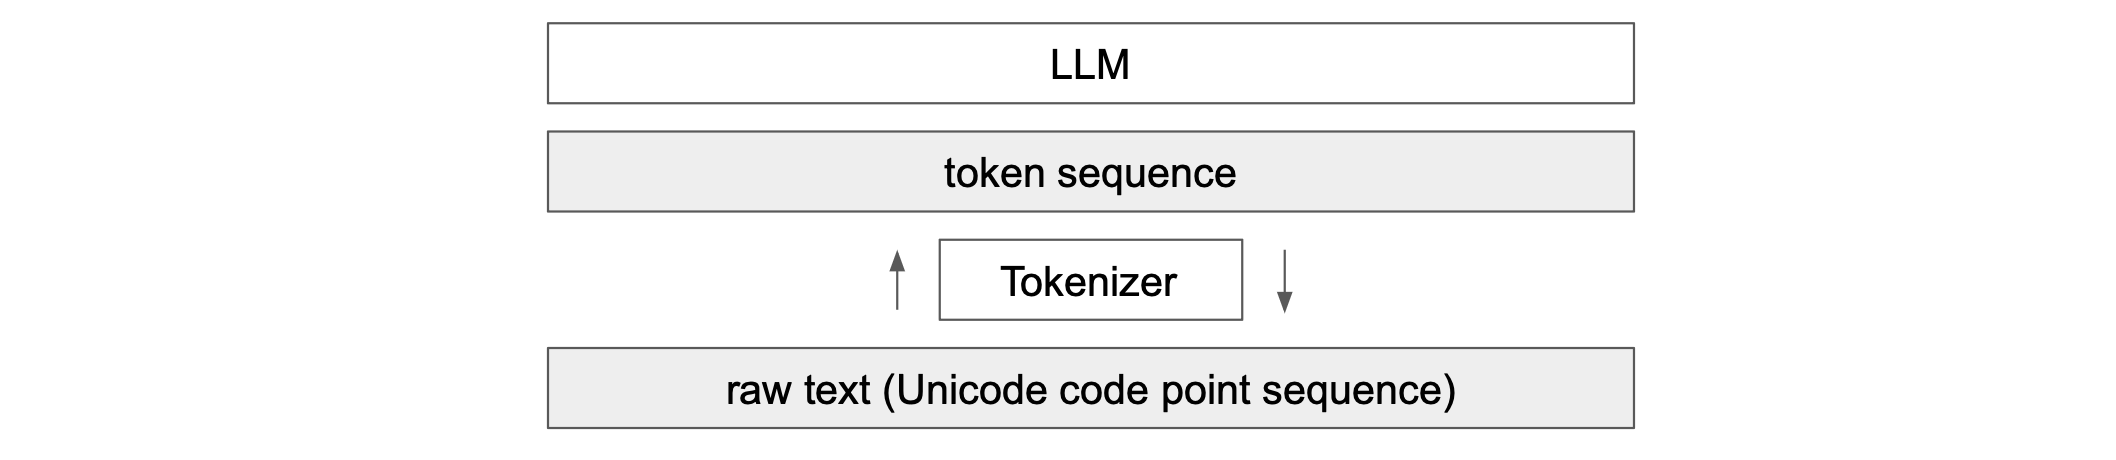

#### **Decoding**

Given a sequence of integers in the range [0, vocab_size], what is the text?


In [ ]:
vocab = {idx: bytes([idx]) for idx in range(256)}   # Initialize vocabulary with single-byte tokens (0–255)

In [ ]:

for (p0, p1), idx in merges.items():
    vocab[idx] = vocab[p0] + vocab[p1]              # Construct new token bytes by concatenating child tokens

def decode(ids):
    # given ids (list of integers), return Python string
    tokens = b"".join(vocab[idx] for idx in ids)    # Reconstruct the full byte sequence from token IDs
    text = tokens.decode("utf-8", errors="replace") # Decode bytes to UTF-8 text, replacing invalid sequences
    return text

print(decode([128]))                                # Decode a single raw-byte token


�


#### **Encoding**

The other way around: Given a string, what are the tokens?


In [ ]:
merges

{(101, 32): 256,
 (105, 110): 257,
 (115, 32): 258,
 (116, 104): 259,
 (101, 114): 260,
 (99, 111): 261,
 (116, 32): 262,
 (226, 128): 263,
 (44, 32): 264,
 (97, 110): 265,
 (111, 114): 266,
 (100, 32): 267,
 (97, 114): 268,
 (101, 110): 269,
 (257, 103): 270,
 (261, 100): 271,
 (121, 32): 272,
 (46, 32): 273,
 (97, 108): 274,
 (259, 256): 275}

In [ ]:
def encode(text):
  # given a string, return list of integers (the tokens)
  tokens = list(text.encode("utf-8"))
  while len(tokens) >= 2:
    stats = get_stats(tokens)
    pair = min(stats, key=lambda p: merges.get(p, float("inf")))
    if pair not in merges:
      break # nothing else can be merged
    idx = merges[pair]
    tokens = merge(tokens, pair, idx)
  return tokens

print(encode(""))

[]


In [ ]:
print(decode(encode("hello world")))

hello world


In [ ]:
text2 = decode(encode(text))
print(text2 == text)

True


In [ ]:
valtext = "Many common characters, including numerals, punctuation, and other symbols, are unified within the standard and are not treated as specific to any given writing system. Unicode encodes thousands of emoji, with the continued development thereof conducted by the Consortium as a part of the standard.[4] Moreover, the widespread adoption of Unicode was in large part responsible for the initial popularization of emoji outside of Japan. Unicode is ultimately capable of encoding more than 1.1 million characters."
valtext2 = decode(encode(valtext))
print(valtext2 == valtext)

True


### **6. Data Sampling With a Sliding Window**

- We train LLMs to generate one word at a time, so we want to prepare the training data accordingly where the next word in a sequence represents the target to predict:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/12.webp" width="700px">

In [ ]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)  # Convert entire corpus to token IDs (the model trains on IDs, not raw strings)
print(len(enc_text))

5145


- For each text chunk, we want the inputs and targets
- Since we want the model to predict the next word, the targets are the inputs shifted by one position to the right

In [ ]:
enc_sample = enc_text[50:]

In [ ]:
context_size = 4 # Window length: number of tokens given as context to predict the next token

x = enc_sample[:context_size] # Input context tokens
y = enc_sample[1:context_size+1]  # Targets: same sequence shifted right by one token (next-token labels)

print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


- One by one, the prediction would look like as follows:

In [ ]:
# # Show the next-token prediction task as the context grows from length 1 to context_size

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i] # The immediate next token after that prefix

    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


In [ ]:
# Same as above, but decoded to human-readable text to verify the training pairs make sense
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


- Now, we implement a simple data loader that iterates over the input dataset and returns the inputs and targets shifted by one

- Install and import PyTorch

In [ ]:
import torch
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu128


- We use a sliding window approach, changing the position by +1:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/13.webp?123" width="700px">

- Create dataset and dataloader that extract chunks from the input text dataset
- Up to now, we manually created (x, y) pairs.
- We want a Dataset that automatically: tokenizes the corpus, creates overlapping context windows, returns (input_ids, target_ids) suitable for next-token prediction.”

- Dataset defines what one training example is, and DataLoader defines how batches are sampled.

In [ ]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text into token IDs (model never sees raw text)
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        assert len(token_ids) > max_length, "Number of tokenized inputs must at least be equal to max_length+1" # "Number of tokenized inputs must at least be equal to max_length+1"


        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]              # Context window
            target_chunk = token_ids[i + 1: i + max_length + 1]    # Same window shifted by one token
            self.input_ids.append(torch.tensor(input_chunk))       # Convert to tensor for PyTorch
            self.target_ids.append(torch.tensor(target_chunk))


    def __len__(self):
        return len(self.input_ids) # Total number of training examples

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx] # One (input, target) pair

In [ ]:
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Use the GPT-2 tokenizer to match the vocabulary used by GPT-style models
    tokenizer = tiktoken.get_encoding("gpt2") # BPE

    # Wrap the text into a Dataset that produces (input_ids, target_ids)
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # DataLoader handles batching, shuffling, and parallel loading
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

- Let's test the dataloader with a batch size of 1 for an LLM with a context size of 4:

In [ ]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

In [ ]:
# Initialize the DataLoader by calling the helper function defined earlier
dataloader = create_dataloader_v1(
    raw_text,      # The string of text
    batch_size=1,  # Number of samples to return at once (here, just one sequence)
    max_length=4,  # Each input sequence will consist of exactly 4 tokens
    stride=4,      # The 'jump' distance;
    shuffle=False  # Do not scramble the data; keep it in the original order of the text
)

# Convert the DataLoader object into a Python iterator so we can fetch batches manually
data_iter = iter(dataloader)

# Fetch the very first batch (contains one input tensor and one target tensor)
first_batch = next(data_iter)

# Display the result to the console to inspect the token IDs . These are the integer IDs for the first 4 tokens in your text (input,target)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [ ]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[1807, 3619,  402,  271]]), tensor([[ 3619,   402,   271, 10899]])]


- An example using stride equal to the context length (here: 4) as shown below:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/14.webp" width="700px">

- We can also create batched outputs
- Note that we increase the stride here so that we don't have overlaps between the batches, since more overlap could lead to increased overfitting

In [ ]:
# Create a DataLoader into a single batch
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,   # Now fetching 8 training examples at once
    max_length=4,
    stride=4,
    shuffle=False
)

# Initialize the iterator
data_iter = iter(dataloader)

# Unpack the next batch into two variables: inputs (X) and targets (Y)
inputs, targets = next(data_iter)

# Print the 8x4 matrix of input token IDs
print("Inputs:\n", inputs)

# Print the 8x4 matrix of target token IDs (each row shifted by 1)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


### **7. Creating Token Embeddings**

- The data is already almost ready for an LLM
- But lastly let us embed the tokens in a continuous vector representation using an embedding layer
- Usually, these embedding layers are part of the LLM itself and are updated (trained) during model training

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/15.webp" width="700px">

- Suppose we have the following four input examples with input ids 2, 3, 5, and 1 (after tokenization):

In [ ]:
input_ids = torch.tensor([2, 3, 5, 1])

In [ ]:
tokenizer.n_vocab

50257

- For the sake of simplicity, suppose we have a small vocabulary of only 6 words and we want to create embeddings of size 3:

In [ ]:
vocab_size = 6 # Define the size of our 'dictionary' (total unique tokens)
output_dim = 3 # Define the size of the vector for each token (how many numbers represent one word)

torch.manual_seed(123) # Set a random seed so the 'random' numbers generated are the same every time we run this
embedding_layer = torch.nn.Embedding(vocab_size, output_dim) # Initialize the embedding layer; essentially a lookup table of shape (6, 3)

- This would result in a 6x3 weight matrix:

In [ ]:
# Access the internal weight matrix of the embedding layer
# This is the 'master list' where all the vector values are stored
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


- For those who are familiar with one-hot encoding, the embedding layer approach above is essentially just a more efficient way of implementing one-hot encoding followed by matrix multiplication in a fully-connected layer, which is described [here](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch02/03_bonus_embedding-vs-matmul/embeddings-and-linear-layers.ipynb)
- Because the embedding layer is just a more efficient implementation that is equivalent to the one-hot encoding and matrix-multiplication approach it can be seen as a neural network layer that can be optimized via backpropagation

- To convert a token with id 3 into a 3-dimensional vector, we do the following:

In [ ]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


- Note that the above is the 4th row in the `embedding_layer` weight matrix
- To embed all four `input_ids` values above, we do

In [ ]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


- An embedding layer is essentially a look-up operation:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/16.webp?123" width="700px">

### **8. Encoding Word Positions**

- Embedding layer convert IDs into identical vector representations regardless of where they are located in the input sequence:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/17.webp" width="700px">

- Positional embeddings are combined with the token embedding vector to form the input embeddings for a large language model:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/18.webp" width="800px">

- The BytePair encoder has a vocabulary size of 50,257:
- Suppose we want to encode the input tokens into a 256-dimensional vector representation:

In [ ]:
vocab_size = 50257 # Define the full vocabulary size
output_dim = 256 # Define the size of the vector for each token (LLMs usually use 768+, but we use 256 here)

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim) # Create the embedding layer

- If we sample data from the dataloader, we embed the tokens in each batch into a 256-dimensional vector
- If we have a batch size of 8 with 4 tokens each, this results in a 8 x 4 x 256 tensor:

In [ ]:
# Create the DataLoader to fetch batches of 8 sequences, each 4 tokens long
max_length = 4
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=max_length,
    stride=max_length,
    shuffle=False
)

# Convert to an iterator and fetch the first batch
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

In [ ]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


In [ ]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
print(token_embeddings)

torch.Size([8, 4, 256])
tensor([[[ 0.3045, -2.2610, -0.4094,  ..., -1.6522, -0.2868,  1.2438],
         [-0.2460,  0.2528,  0.2237,  ..., -0.7093, -0.6564, -1.2014],
         [ 0.4986,  0.1621,  0.6822,  ...,  1.1171,  0.2367,  0.2138],
         [-0.5436,  0.6707,  2.0537,  ..., -0.6127,  0.5454, -0.9175]],

        [[-0.4044,  0.3227,  1.0297,  ...,  0.0570,  0.7727, -0.0346],
         [-0.2779,  0.7304,  2.0882,  ...,  1.0014,  0.1509, -0.5499],
         [-1.4237,  0.5973, -1.3234,  ..., -0.4272,  1.0466, -0.1104],
         [-1.5506,  0.1693,  1.4931,  ..., -0.3387, -1.0787, -1.2689]],

        [[ 1.4963,  0.5346,  0.8751,  ...,  2.5655, -0.7914,  1.6417],
         [-0.5089, -1.4528, -0.4107,  ...,  0.7509,  0.4721,  0.3420],
         [ 0.0118, -1.0189,  0.1589,  ...,  0.5212, -0.2544,  0.9034],
         [-0.6605,  0.8879, -0.3432,  ...,  0.0128,  0.4897, -0.2956]],

        ...,

        [[ 1.2109, -1.1724, -1.9072,  ...,  0.6573, -2.3168,  2.6120],
         [ 0.4538,  1.3213,  0.02

- GPT-2 uses absolute position embeddings, so we just create another embedding layer:

In [ ]:
# The maximum number of tokens the model can process at once (4 in this case)
context_length = max_length

# Create an embedding layer for positions (0 to 3)
# It has 4 rows (one for each index) and 256 columns (to match token embeddings)
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

# Print the weight matrix: the actual vectors representing positions 0, 1, 2, and 3
print(pos_embedding_layer.weight)

Parameter containing:
tensor([[-1.4693,  1.0024,  0.6403,  ..., -0.7098, -0.4741,  1.3287],
        [-0.3833,  0.5006,  2.1007,  ..., -0.1256,  0.8334, -1.8840],
        [ 0.3221,  0.9576, -1.5949,  ...,  0.4771, -0.7206,  0.2753],
        [ 0.1482, -1.1207,  1.1867,  ...,  0.5207, -1.0125, -0.3823]],
       requires_grad=True)


In [ ]:
torch.arange(max_length)

tensor([0, 1, 2, 3])

In [ ]:
# torch.arange(max_length) creates a tensor of [0, 1, 2, 3]
# Passing this to the layer retrieves the specific vectors for those 4 positions
pos_embeddings = pos_embedding_layer(torch.arange(max_length))

# Display the dimensions of the positional vectors
# Expected: torch.Size([4, 256])
print(pos_embeddings.shape)

# Print the actual numerical values (the "GPS coordinates" for each slot)
print(pos_embeddings)

torch.Size([4, 256])
tensor([[-1.4693,  1.0024,  0.6403,  ..., -0.7098, -0.4741,  1.3287],
        [-0.3833,  0.5006,  2.1007,  ..., -0.1256,  0.8334, -1.8840],
        [ 0.3221,  0.9576, -1.5949,  ...,  0.4771, -0.7206,  0.2753],
        [ 0.1482, -1.1207,  1.1867,  ...,  0.5207, -1.0125, -0.3823]],
       grad_fn=<EmbeddingBackward0>)


- To create the input embeddings used in an LLM, we simply add the token and the positional embeddings:

In [ ]:
# Check the shape of the token-only data (8 batches, 4 tokens, 256 features)
token_embeddings.shape

torch.Size([8, 4, 256])

In [ ]:
# Add the two tensors together: (8, 4, 256) + (4, 256)
# PyTorch 'broadcasts' the positional vectors across all 8 batch items automatically
input_embeddings = token_embeddings + pos_embeddings

# Display the final shape; it remains (8, 4, 256)
print(input_embeddings.shape)

# Print the final numerical representation that will actually enter the LLM
print(input_embeddings)

torch.Size([8, 4, 256])
tensor([[[-1.1648, -1.2586,  0.2309,  ..., -2.3620, -0.7609,  2.5726],
         [-0.6292,  0.7534,  2.3243,  ..., -0.8349,  0.1770, -3.0854],
         [ 0.8206,  1.1197, -0.9127,  ...,  1.5942, -0.4839,  0.4891],
         [-0.3954, -0.4500,  3.2404,  ..., -0.0919, -0.4671, -1.2998]],

        [[-1.8736,  1.3251,  1.6700,  ..., -0.6528,  0.2985,  1.2941],
         [-0.6612,  1.2310,  4.1889,  ...,  0.8759,  0.9843, -2.4340],
         [-1.1017,  1.5549, -2.9182,  ...,  0.0499,  0.3260,  0.1649],
         [-1.4024, -0.9514,  2.6798,  ...,  0.1820, -2.0912, -1.6512]],

        [[ 0.0271,  1.5370,  1.5154,  ...,  1.8557, -1.2655,  2.9704],
         [-0.8922, -0.9522,  1.6900,  ...,  0.6254,  1.3055, -1.5421],
         [ 0.3339, -0.0613, -1.4360,  ...,  0.9983, -0.9750,  1.1788],
         [-0.5124, -0.2328,  0.8435,  ...,  0.5335, -0.5228, -0.6778]],

        ...,

        [[-0.2584, -0.1700, -1.2669,  ..., -0.0525, -2.7910,  3.9407],
         [ 0.0705,  1.8219,  2.12

- In the initial phase of the input processing workflow, the input text is segmented into separate tokens
- Following this segmentation, these tokens are transformed into token IDs based on a predefined vocabulary:

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/ch02_compressed/19.webp" width="600px">

# **B) Running Pre-trained LLMs and Comparing LLM Tokenizers**



## **[OPTIONAL]** - Installing Packages

If you are viewing this notebook on Google Colab (or any other cloud vendor), you need to **uncomment and run** the following codeblock to install the dependencies for this section:

---

💡 **NOTE**: We will want to use a GPU to run the examples in this notebook. In Google Colab, go to
**Runtime > Change runtime type > Hardware accelerator > GPU > GPU type > T4**.

---

In [ ]:
%%capture
!pip install --upgrade transformers==4.41.2 sentence-transformers==3.0.1 gensim==4.3.2 scikit-learn==1.5.0 accelerate==0.31.0 peft==0.11.1 scipy==1.10.1 numpy==1.26.4

## **0) Comparing Trained LLM Tokenizers**


In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# A list of RGB color codes (Soft pastels) used for the background of the tokens
colors_list = [
    '102;194;165', '252;141;98', '141;160;203',
    '231;138;195', '166;216;84', '255;217;47'
]

def show_tokens(sentence, tokenizer_name):
    # Load the specific tokenizer (e.g., GPT-2, Llama, or Phi-3)
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

    # Convert the string sentence into a list of integer Token IDs
    token_ids = tokenizer(sentence).input_ids

    # Loop through each token ID to decode and print it
    for idx, t in enumerate(token_ids):
        # Use ANSI escape codes to set the background color and print the decoded word
        # \x1b[0;30;48;2;...m creates the colored background in the terminal
        print(
            f'\x1b[0;30;48;2;{colors_list[idx % len(colors_list)]}m' +
            tokenizer.decode(t) +
            '\x1b[0m',
            end=' ' # Space out the tokens so they don't overlap
        )

In [ ]:
text = """
English and CAPITALIZATION
🎵 鸟
show_tokens False None elif == >= else: two tabs:"    " Three tabs: "       "
12.0*50=600
"""

In [ ]:
show_tokens(text, "bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[CLS] english and capital ##ization [UNK] [UNK] show _ token ##s false none eli ##f = = > = else : two tab ##s : " " three tab ##s : " " 12 . 0 * 50 = 600 [SEP] 

- BERT uses WordPiece tokenization. It recognizes "capital" as a root word and ##ization as a common suffix. The ## indicates that this token is a continuation of the previous word, not a new word.
- The musical note (🎵) and the Chinese character (鸟) are both rendered as [UNK]. This specific BERT model was trained primarily on English text.
- [CLS]: Added to the very beginning. This is a "Classification" token used by BERT to represent the meaning of the entire sequence.
- Python Keywords: Keywords like false, none, and elif are recognized as single tokens because they appear frequently in the training data.
- Operators: Notice how == and >= are split into individual tokens like = = and > =. BERT often treats punctuation and math symbols as individual units.

In [ ]:
show_tokens(text, "bert-base-cased")

- Case Preservation: Unlike the "uncased" version, this model keeps "English" capitalized.

- Aggressive Splitting: Because it has to store both "A" and "a", its vocabulary fills up faster. This forces it to break words into much smaller fragments (e.g., CA ##PI ##TA ##L ##I ##Z ##AT ##ION).

- Symbol Limits: Like its uncased brother, it still returns [UNK] for emojis and non-English characters.

- Structural Consistency: Still maintains the [CLS] and [SEP] tokens for classification tasks.

In [ ]:
show_tokens(text, "gpt2")

- Case Sensitivity: Unlike "bert-base-uncased," GPT-2 is cased. It preserves the original capitalization, keeping "English" and "CAPITALIZATION" exactly as they were written.

- Byte-Pair Encoding (BPE) Splitting: GPT-2 uses BPE to break words into sub-units. For example, "CAPITALIZATION" is split into CAP, ITAL, IZ, and ATION.

- Visualizing Spaces (The "Ġ" Symbol): If you look closely at the colored blocks, some words have a small gap or leading space. GPT-2 treats spaces as part of the following token (often represented internally by a Ġ character).

- Handling Emojis and Symbols: Unlike BERT, which showed [UNK], GPT-2 can represent complex symbols like the musical note (🎵) and the Chinese character (鸟). However, it doesn't always have a single token for them; it often breaks them down into multiple "byte-level" tokens (the colorful sequence of small blocks).

- Whitespace Preservation: GPT-2 is much better at "seeing" structure. It captures the tabs and multiple spaces as individual tokens, whereas BERT largely ignored them.

- Number and Math Logic: Numbers are broken down into smaller chunks (e.g., 12 . 0). This allows the model to build larger numbers from a small set of digit-based tokens.


In [ ]:
show_tokens(text, "google/flan-t5-small")

- Case Sensitivity: Like GPT-2 and BERT-cased, Flan-T5 is cased and preserves the capitalization of "English" and "CAPITALIZATION".

- Whitespace as a Character: It treats spaces as actual characters (indicated by the small colored blocks before words), ensuring that the structural layout of the text is preserved.

- Sub-word Splitting: It aggressively breaks down large or complex words into smaller components (e.g., "CAPITALIZATION" becomes CA PI TAL IZ ATION).

- Unknown Character Handling: Similar to BERT, it cannot recognize the emoji or Chinese character, replacing them with the <unk> (unknown) token.

- Special End Token: It appends a </s> (end-of-string) token to indicate the completion of the text sequence.

- Code and Math: It breaks down logical operators (like ==) and numerical expressions (like 12.0) into individual constituent characters or small sub-units.

In [ ]:
show_tokens(text, "microsoft/Phi-3-mini-4k-instruct")

- Case Preservation: Like GPT-2, it preserves capitalization (e.g., "English" and "CAPITALIZATION").

- Sub-word Efficiency: It breaks complex words into logical chunks, such as C AP IT AL IZ ATION.

- Byte-Level Fallback: For the emoji and Chinese characters, it doesn't show an unknown token like [UNK]. Instead, it breaks them into a series of byte-level tokens (the colorful sequence of diamond symbols), allowing the model to "see" every character even if it's not in the common vocabulary.

- Whitespace Sensitive: It captures tabs and multiple spaces as distinct tokens, which is critical for understanding code structure.

- Clean Generation: It does not require structural prefixes like [CLS], making it streamlined for chat and instruction-following tasks.

In [ ]:
# The official is `tiktoken` but this the same tokenizer on the HF platform
show_tokens(text, "Xenova/gpt-4")

In [ ]:
# You need to request access before being able to use this tokenizer
show_tokens(text, "bigcode/starcoder2-15b")

- Code-Centric Efficiency: As a model built for programming, StarCoder2 is exceptionally efficient with technical syntax. Notice how it handles CAPITAL and IZATION as two large, logical blocks compared to more fragmented general-purpose models.

- Whitespace Preservation: It treats tabs and multiple spaces as unique, distinct tokens. This is critical because, in many programming languages (like Python), indentation carries functional meaning.

- Symbol Handling: It tends to group logical operators like == and >= more cleanly, viewing them through the lens of programming logic rather than just individual punctuation marks.

- Byte-Level Fallback: Like the other modern decoder models (GPT-2, Phi-3, Galactica), it handles emojis (🎵) and non-Latin characters (鸟) by breaking them into byte-level fragments (the diamond symbols) instead of using an "unknown" tag. This ensures no data is lost during encoding.

- Case Sensitivity: It preserves capitalization perfectly, which is essential for distinguish between variables like myVariable and MyVariable in code.

## **1) Downloading and Running An LLM**

The first step is to load our model onto the GPU for faster inference. Note that we load the model and tokenizer separately and keep them as such so that we can explore them separately.

In [ ]:
from google.colab import userdata
HF_TOKEN = userdata.get('hfkey')

#### AutoTokenizer: The Bridge to Numbers
#### The Core Problem

A neural network is, at its heart, a giant math function. It takes numbers in, does matrix multiplications, and spits numbers out. It has **no concept of letters, words, or sentences**.

So before any text reaches the model, it must be converted into a sequence of integers. That is the tokenizer's job.




#### What Exactly Is a Token?

A token is the smallest unit the model works with. It is usually a sub-word — not quite a character, not quite a full word.

```
"unbelievable"  →  ["un", "believ", "able"]      ← 3 tokens
"cat"           →  ["cat"]                         ← 1 token
"ChatGPT"       →  ["Chat", "G", "PT"]            ← 3 tokens
```

Each token maps to a unique integer ID in the model's vocabulary:

```
"un"      →  4895
"believ"  →  7283
"able"    →  1075
```

This mapping table is fixed — it is learned during tokenizer training and never changes.


#### Why `Auto` in AutoTokenizer?

Different models use different tokenization schemes:

| Model Family | Tokenizer Type |
|---|---|
| BERT, RoBERTa | WordPiece |
| GPT-2, GPT-4 | Byte-Pair Encoding (BPE) |
| LLaMA, Mistral | SentencePiece (BPE variant) |
| Phi-3 | tiktoken-style BPE |

`AutoTokenizer.from_pretrained("model-name")` automatically detects which tokenizer the model needs and loads it — you do not need to know or specify the type manually.

```python
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("microsoft/phi-3-mini-4k-instruct")
```



#### Key Responsibilities

#### 1. Standardization — Exact Reproducibility

The tokenizer used at **inference time must be identical** to the one used at **training time**.

Why? The model learned associations between token IDs and meanings. If you swap tokenizers, the same string produces different IDs — the model sees completely different inputs and produces garbage.

```python
# These two tokenizers produce DIFFERENT IDs for the same text
tokenizer_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
tokenizer_gpt2 = AutoTokenizer.from_pretrained("gpt2")

text = "Hello world"
print(tokenizer_bert(text)["input_ids"])   # [101, 7592, 2088, 102]
print(tokenizer_gpt2(text)["input_ids"])   # [15496, 995]
```

`AutoTokenizer` guarantees you get the right one automatically.



#### 2. Special Tokens — Structural Markers

Models are not just fed raw text. They need structural signals embedded in the token sequence to understand context.

**BERT-style models** wrap every input:
```
[CLS] The cat sat on the mat [SEP]
  ↑                            ↑
"Start of sequence"        "End of sequence"
```

**GPT-style models** use an end-of-text marker:
```
The cat sat on the mat <|endoftext|>
```

**Chat/instruction models** (like Phi-3) use full conversation templates:
```
<|user|>
What is BPE?
<|end|>
<|assistant|>
```

`AutoTokenizer` inserts all of these automatically — you just pass raw text.

```python
inputs = tokenizer("What is BPE?", return_tensors="pt")
# Special tokens are added silently
```

Without these markers, the model cannot tell where a prompt ends, where an answer begins, or whether it is doing classification vs. generation.


#### 3. Padding and Truncation — Fitting the Context Window

Neural networks process fixed-size batches. Every sequence in a batch must be the same length.

**Padding** — Short sequences get padded with a special `[PAD]` token:
```
Sequence 1: [101, 7592, 2088, 102, 0, 0, 0]   ← padded
Sequence 2: [101, 7592, 1996, 3899, 2003, 9005, 102]
```

**Truncation** — Long sequences get cut to fit the model's maximum length (e.g., 4096 tokens for Phi-3):
```python
inputs = tokenizer(
    very_long_text,
    padding=True,
    truncation=True,
    max_length=4096,
    return_tensors="pt"
)
```

The tokenizer also produces an **attention mask** — a binary array that tells the model which positions are real tokens (1) and which are padding (0), so padding doesn't influence the computation.

```
input_ids:      [101, 7592, 2088, 102,  0,   0 ]
attention_mask: [  1,    1,    1,   1,  0,   0 ]
```

---

#### What the Tokenizer Returns

```python
output = tokenizer("Hello world", return_tensors="pt")

# output contains:
# {
#   "input_ids":      tensor([[101, 7592, 2088, 102]]),   ← integer IDs
#   "attention_mask": tensor([[  1,    1,    1,   1]])     ← 1=real, 0=pad
# }
```

These tensors go directly into the model.

---


The tokenizer converts raw text → integer IDs (with all structural markers added), so the model always receives input in exactly the same format it was trained on.

### AutoModelForCausalLM — The Inference Engine


#### Unpacking the Name

```
Auto  Model  For  Causal  LM
 │      │     │     │      │
 │      │     │     │      └── Language Model (predicts tokens)
 │      │     │     └───────── Causal (left-to-right, no peeking ahead)
 │      │     └─────────────── Task-specific head attached on top
 │      └───────────────────── The transformer neural network
 └──────────────────────────── Auto-detects architecture from model name
```

---

## The Big Picture: What Does This Class Actually Do?

When you write:

```python
from transformers import AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained("microsoft/phi-3-mini-4k-instruct")
```

You are loading:

1. The **architecture** — transformer layers, attention heads, feed-forward networks
2. The **weights** — billions of learned floating-point numbers (parameters)
3. The **LM head** — the final layer that produces token probabilities
All three live inside this single object.

#### Core Concept 1: Next-Token Prediction

This is the fundamental task the model was trained on.

Given a sequence of tokens, predict what comes next.

```
Input:   "The cat sat on the"
Predict: "mat"  (probability 0.73)
         "floor" (probability 0.11)
         "roof"  (probability 0.04)
         ...
```

The model assigns a probability to **every token in the vocabulary** at every step.

Training on this simple task across trillions of tokens is how the model learns grammar, facts, reasoning, and language patterns — all implicitly baked into the weights.

---

#### Core Concept 2: Why "Causal"?

"Causal" means the model can only look **left** — it sees past tokens, never future ones.

```
Tokens:  [The]  [cat]  [sat]  [on]  [the]  [mat]
           ↑      ↑      ↑     ↑      ↑      ↑
           │      │      │     │      │      │
When predicting "mat", the model sees:
           ✓      ✓      ✓     ✓      ✓      ✗ (blocked)
```

This is enforced with a **causal attention mask** — a triangular mask that zeroes out any attention to future positions.

The alternative (used in BERT) is **bidirectional** — the model sees the whole sentence at once, which is great for understanding but cannot generate text autoregressively.

| | BERT (Bidirectional) | GPT / Phi / LLaMA (Causal) |
|---|---|---|
| Sees future tokens? | Yes | No |
| Good for | Classification, NLU | Text generation, chat |
| Generates text? | Not natively | Yes |

---

#### Core Concept 3: The Language Modeling Head

The base transformer produces a **hidden state vector** for each token position — a dense numerical representation of meaning at that position, typically 2048 to 8192 numbers wide.

```
Input token IDs  →  [Transformer Layers]  →  Hidden states
                                                    ↓
                                             [LM Head (linear layer)]
                                                    ↓
                                          Logits over vocabulary
                                          (one number per token in vocab)
                                                    ↓
                                             [Softmax]
                                                    ↓
                                          Probability distribution
```

The **LM head** is a single linear layer that projects the hidden state to the vocabulary size:

```
hidden_state shape: [batch, seq_len, hidden_dim]   e.g. [1, 10, 3072]
       ↓  linear layer (no activation)
logits shape:       [batch, seq_len, vocab_size]   e.g. [1, 10, 32064]
```

Every position produces 32,064 numbers (for Phi-3) — one per vocabulary token. Softmax turns these into probabilities. The next token is sampled or greedy-picked from this distribution.

---

#### Core Concept 4: Weight Management

A model like Phi-3-mini has **3.8 billion parameters**. Each is a 32-bit float (4 bytes) by default.

```
3.8B × 4 bytes = ~15 GB  (fp32)
3.8B × 2 bytes = ~7.5 GB (fp16 / bf16)
3.8B × 1 byte  = ~3.8 GB (int8 quantized)
```

`from_pretrained` handles loading this into memory, with options to control precision:

```python
import torch

model = AutoModelForCausalLM.from_pretrained(
    "microsoft/phi-3-mini-4k-instruct",
    torch_dtype=torch.float16,   # use half precision → saves memory
    device_map="auto"            # auto-split across CPU/GPU if needed
)
```

Without `device_map="auto"`, the whole model loads into CPU RAM and inference is extremely slow.

---

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# Load the actual neural network (the model)
model = AutoModelForCausalLM.from_pretrained(
    "microsoft/Phi-3-mini-4k-instruct", # The specific model ID from Hugging Face
    device_map="cuda",                  # Automatically move the model to your GPU
    torch_dtype="auto",                 # Use the best precision (e.g., float16) for your hardware
    trust_remote_code=False,            # Security flag: don't run custom code from the repo
)

# Load the tokenizer (the 'translator') that matches this specific model
tokenizer = AutoTokenizer.from_pretrained("microsoft/Phi-3-mini-4k-instruct")

In [ ]:
# Define the instruction for the model using its specific chat format
prompt = "Write an email apologizing to Sarah for the tragic gardening mishap. Explain how it happened.<|assistant|>"

# Convert the text into a tensor of Token IDs and move them to the GPU (cuda)
# 'return_tensors="pt"' ensures the output is a PyTorch tensor
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda")

# Use the model's 'generate' function to predict the next tokens
generation_output = model.generate(
  input_ids=input_ids,      # The 'context' the model looks at
  max_new_tokens=150         # Limit the response to 20 new words/tokens
)

In [ ]:
print(input_ids)

In [ ]:
for id in input_ids[0]:
   print(tokenizer.decode(id))

In [ ]:
generation_output

In [ ]:
print(tokenizer.decode(generation_output[0]))

In [ ]:
import torch

print(tokenizer.decode(torch.tensor(3323)))
print(tokenizer.decode(torch.tensor(622)))
print(tokenizer.decode(torch.tensor([3323, 622])))
print(tokenizer.decode(torch.tensor(29901)))

---
## **2) Understanding Generation: Parameters That Control What the LLM Says**

Running an LLM is not just `model.generate(input_ids)`. The model outputs a **probability distribution** over its entire vocabulary at every step. How you *sample* from that distribution determines whether the output is creative, focused, repetitive, or random.



### The Big Picture: From Logits → Token

<img src="https://huggingface.co/blog/assets/02_how-to-generate/greedy_search.png" width="700">

*At each step, the model produces a vector of raw scores (logits) — one per vocabulary token. Generation strategies decide how to pick the next token from those scores.*


### Step 0 — Install / Import


In [ ]:

# transformers is already installed; make sure it is recent enough
!pip install -q transformers torch


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

# ── Load GPT-2 (117M parameters — runs fine on CPU) ──────────────────────
gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
gpt2_model     = AutoModelForCausalLM.from_pretrained("gpt2")
gpt2_model.eval()   # Disable dropout — we are doing inference, not training

print("GPT-2 loaded ✓")
print(f"Parameters: {sum(p.numel() for p in gpt2_model.parameters()):,}")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 loaded ✓
Parameters: 124,439,808


### Peek inside the model


In [ ]:
# The embedding table: 50 257 tokens × 768 dimensions
print(gpt2_model.transformer.wte)
print()

# 12 Transformer decoder blocks
print(f"Number of Transformer layers: {len(gpt2_model.transformer.h)}")

# The language-modelling head maps hidden states → logits over vocabulary
print(f"LM head shape: {gpt2_model.lm_head.weight.shape}")


Embedding(50257, 768)

Number of Transformer layers: 12
LM head shape: torch.Size([50257, 768])


### Helper: `generate_text` wrapper


In [ ]:
def generate_text(prompt, model, tokenizer,
                  max_new_tokens=100,
                  # --- decoding strategy ---
                  do_sample=True,
                  temperature=1.0,
                  top_k=50,
                  top_p=0.95,
                  num_beams=1,
                  repetition_penalty=1.0,
                  # --- output ---
                  skip_special_tokens=True):
    """
    Encode *prompt*, run generation with the chosen strategy, decode the output.
    Returns the generated text (not including the prompt).
    """
    input_ids = tokenizer.encode(prompt, return_tensors="pt")

    with torch.no_grad():
        output_ids = model.generate(
            input_ids,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            num_beams=num_beams,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id,  # suppress a warning in GPT-2
        )

    # Decode only the *newly generated* tokens (slice off the prompt)
    new_tokens = output_ids[0, input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=skip_special_tokens)


### 1. Greedy Decoding — always pick the most likely next token

At each step, the model looks at the probability distribution over the entire vocabulary and simply picks the token with the highest score — no randomness, no lookahead. Think of it as always taking the most obvious next word, one step at a time.

**Pro:** deterministic, fast.  
**Con:** tends to produce repetitive, boring text. Once the model commits to a bad word, it doubles down.

In [ ]:
prompt = "The key idea behind transformers is"

# do_sample=False → greedy (no randomness)
greedy_out = generate_text(
    prompt, gpt2_model, gpt2_tokenizer,
    do_sample=False, max_new_tokens=80
)
print("GREEDY OUTPUT:")
print(prompt + greedy_out)


### 2. Temperature — control the sharpness of the probability distribution

### What Even Is Temperature?

Temperature is borrowed from physics — in thermodynamics, high temperature means particles move more chaotically and unpredictably; low temperature means they settle into order. Same intuition here: **high T = chaotic/creative outputs, low T = settled/predictable outputs.**

Think of it like a **confidence dial** on the model. At every step, the model has a ranked list of candidate next tokens with associated probabilities. Temperature doesn't change the ranking — it changes **how steep the gap is** between rank 1 and rank 2, 3, 4...


```
Logits (raw):   cat=5.2   dog=4.8   fish=1.1   table=0.3

T=0.5 (sharp):  cat=91%   dog=8%    fish=~0%   table=~0%   ← model is very sure
T=1.0 (normal): cat=55%   dog=40%   fish=4%    table=1%    ← default
T=2.0 (flat):   cat=35%   dog=32%   fish=20%   table=13%   ← anything could happen
```

At low T, the model almost always picks `cat`. At high T, `table` starts getting real chances — which is sometimes creative, sometimes incoherent.



### The Math

The model's raw output is a list of logits — one score per vocabulary token. Temperature is a single number you divide those scores by before converting them to probabilities. A low T amplifies the gap between confident and unlikely tokens; a high T shrinks it, making the model less sure of itself.

Before sampling, each logit $z_i$ is divided by **T**:

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

This is just softmax — but with the scores scaled before exponentiation.

---

## Effect of Different Values

| Temperature | Effect |
|-------------|--------|
| T → 0 | Approaches greedy: almost all probability on the top token |
| T = 1 | Unmodified distribution (default) |
| T > 1 | Flatter distribution → more surprising / random outputs |


In [ ]:
prompt = "Once upon a time in a kingdom far away,"

for temp in [0.2, 0.7, 1.0, 1.5]:
    out = generate_text(
        prompt, gpt2_model, gpt2_tokenizer,
        do_sample=True, temperature=temp,

        max_new_tokens=40
    )
    print(f"\n── Temperature {temp} ──")
    print(prompt + out)


### When to Use What

| Use Case | Recommended T |
|---|---|
| Factual Q&A, code generation | 0.1 – 0.4 |
| Chat / general assistant | 0.7 – 1.0 |
| Creative writing, brainstorming | 1.0 – 1.5 |
| Exploration / diversity sampling | > 1.5 (use carefully) |

### 3.Top-k Sampling — restrict the candidate pool to the k highest-probability tokens

Greedy decoding picks just 1 token; pure sampling picks from all 50,000+. Top-k is the middle ground — at each step, throw away every token except the k most likely ones, then sample freely within that shortlist. This prevents the model from ever randomly landing on a bizarre low-probability token, while still keeping enough variety to avoid repetition.

After sorting all tokens by probability, only the top **k** are kept. Their probabilities are re-normalised before sampling.

```
Full vocab (50 257 tokens) → keep top k → renormalise → sample
```

**Good default:** `top_k=50`. Very large k ≈ no filtering; k=1 ≈ greedy.


In [ ]:
prompt = "The future of artificial intelligence will"

for k in [1, 10, 50, 200]:
    out = generate_text(
        prompt, gpt2_model, gpt2_tokenizer,
        do_sample=True, temperature=1.0,
        top_k=k, top_p=1.0,
        max_new_tokens=40
    )
    label = "greedy" if k == 1 else f"top_k={k}"
    print(f"\n── {label} ──")
    print(prompt + out)


### 4. Top-p (Nucleus) Sampling — adaptive pool size

#### The Problem with Top-k

Top-k always keeps exactly k tokens — even when the model is extremely confident about the next word. If the model is 99% sure the next token is `"the"`, you are still sampling from 50 candidates, introducing unnecessary noise. Top-p fixes this by making the pool size **a function of the model's own confidence**.

---

## How It Works

Sort tokens by probability (highest first). Keep adding tokens to the *nucleus* until their cumulative probability ≥ **p**. Sample only from the nucleus.

```
Sorted tokens:   "cat"=0.60  "dog"=0.25  "fish"=0.10  "table"=0.03  "sky"=0.02 ...

With top_p=0.95:
  0.60              → cumsum = 0.60  (keep)
  0.60 + 0.25       → cumsum = 0.85  (keep)
  0.85 + 0.10       → cumsum = 0.95  ✓ threshold reached → stop

Nucleus = ["cat", "dog", "fish"]  — only 3 tokens out of 50,257
```

Re-normalise these 3 probabilities and sample from them. Everything below the threshold is simply discarded.



#### Adaptive Pool Size

The pool size adapts dynamically based on how spread out the distribution is:

- When the model is **very confident** → nucleus is tiny (e.g., 3 tokens reach p=0.95)
- When the model is **uncertain** → nucleus is large (e.g., 500 tokens needed to reach p=0.95)
This is what top-k cannot do. A fixed k=50 is too loose when the model is confident, and potentially too tight when it is genuinely unsure between many plausible continuations. Top-p automatically scales with the situation.


In [ ]:
prompt = "The ocean is"

for p in [0.5, 0.80, 0.95, 1.0]:
    out = generate_text(
        prompt, gpt2_model, gpt2_tokenizer,
        do_sample=True, temperature=1.0,
        top_k=0,        # disable top-k
        top_p=p,
        max_new_tokens=40
    )
    print(f"\n── top_p={p} ──")
    print(prompt + out)


### 5.Combining top_k + top_p (the recommended default)

In practice, top_k and top_p are often used **together** as a two-stage filter:
1. Keep only the top-k tokens.
2. Within those k tokens, further restrict to the nucleus (top-p).


In [ ]:
prompt = "Scientists have recently discovered that"

# The combination OpenAI often recommends: top_k=50, top_p=0.95, temp=0.7
out = generate_text(
    prompt, gpt2_model, gpt2_tokenizer,
    do_sample=True,
    temperature=0.7,
    top_k=50,
    top_p=0.95,
    max_new_tokens=100
)
print("Combined (top_k=50, top_p=0.95, temp=0.7):")
print(prompt + out)


### 6. Beam Search — explore multiple hypotheses

#### The Problem with Greedy (Motivation)

Greedy decoding commits to one token at each step. This creates a trap: a locally good choice can lead to a globally bad sentence.

```
Prompt: "The weather today is"

Greedy picks:   "nice"  → "nice and"  → "nice and sunny"   ← fine
                                                              but what if...
                "nice"  → "nice but"  → dead end, awkward continuation
```

Once greedy picks `"nice"`, it is stuck. It never backtracks. Beam search keeps multiple paths alive so a slightly worse first token can still lead to the best overall sentence.



### How It Works

Instead of committing to one token at each step, beam search keeps the **B best partial sequences** (beams) alive simultaneously.

```
Step 1: expand prompt → keep top-B next tokens
Step 2: expand each beam → keep top-B of B×vocab candidates
...
Return the beam with the highest overall score.
```

### Concrete Example (B=2)

```
Prompt: "The cat"

Step 1 — expand prompt, keep top 2:
  Beam 1: "The cat sat"    (score: -0.3)
  Beam 2: "The cat ran"    (score: -0.5)

Step 2 — expand each beam, generate B×vocab candidates, keep top 2:
  From Beam 1: "The cat sat on"   (score: -0.6)
               "The cat sat and"  (score: -0.9)
  From Beam 2: "The cat ran away" (score: -0.7)
               "The cat ran fast" (score: -1.1)

  Keep top 2 overall:
  Beam 1: "The cat sat on"   (score: -0.6)  ✓
  Beam 2: "The cat ran away" (score: -0.7)  ✓

Step 3 — repeat until EOS or max length
  Return the beam with the highest final score.
```

Scores are log-probabilities (negative numbers; closer to 0 = better). The final score is the sum of log-probs across all tokens — i.e., the joint probability of the whole sequence.


#### Why This Helps

Greedy might pick `"ran"` at step 1 and then get stuck. Beam search keeps `"sat"` alive in parallel, so even if `"ran"` looks slightly better initially, the fuller sequence `"sat on the mat"` can outscore `"ran awkwardly"` by the end.

It is not exhaustive search (that would be exponential) — it is a **bounded width search** that approximates the best sequence without evaluating every possible path.

---

#### Cost

Each beam is a full forward pass through the model:

```
Greedy:       1 forward pass per step
Beam Search:  B forward passes per step  (B=5 → 5× more compute)
```

For long outputs or large B, this becomes expensive fast.


In [ ]:
prompt = "The recipe for a perfect sourdough bread includes"

for n_beams in [1, 3, 5]:
    out = generate_text(
        prompt, gpt2_model, gpt2_tokenizer,
        do_sample=False,   # beam search is deterministic
        num_beams=n_beams,
        max_new_tokens=60
    )
    label = "greedy" if n_beams == 1 else f"{n_beams} beams"
    print(f"\n── {label} ──")
    print(prompt + out)


### 7. Repetition Penalty — discourage the model from repeating itself

Any token that has already appeared in the generated sequence has its logit *divided* by the penalty factor before softmax:

$$z_i^{\\text{new}} = z_i \;/\; \\text{penalty} \quad \\text{if } i \\text{ already appeared}$$

Values around **1.2–1.3** work well. 1.0 = no penalty.


In [ ]:
prompt = "The cat sat on the mat and"

for penalty in [1.0, 1.2, 1.5]:
    out = generate_text(
        prompt, gpt2_model, gpt2_tokenizer,
        do_sample=True, temperature=0.9, top_k=50,
        repetition_penalty=penalty,
        max_new_tokens=60
    )
    print(f"\n── repetition_penalty={penalty} ──")
    print(prompt + out)


###  Quick Reference: Generation Parameter Cheat-Sheet

| Parameter | What it does | Typical value |
|-----------|--------------|---------------|
| `do_sample=False` | Greedy / beam search | — |
| `temperature` | Scales logits before softmax | 0.7 – 1.0 |
| `top_k` | Keep only top-k tokens | 50 |
| `top_p` | Nucleus: keep tokens until cumulative p | 0.92 – 0.95 |
| `num_beams` | Number of parallel beams | 1 (sample) / 4 (beam) |
| `repetition_penalty` | Down-weight repeated tokens | 1.1 – 1.3 |
| `max_new_tokens` | Hard cap on generated length | task-dependent |



## **3) Running Multiple LLMs: GPT-2 vs. Phi-3 vs. Mistral via `pipeline`**

The Hugging Face `pipeline` API is the fastest way to run a model end-to-end. It wraps tokeniser + model + post-processing into a single function call.

```python
from transformers import pipeline
gen = pipeline("text-generation", model="gpt2")
gen("Once upon a time", max_new_tokens=50)
```


### Architecture Recap: GPT-2 vs Phi-3-mini vs Mistral-7B

| Model | Size | Architecture | Context | Best for |
|-------|------|--------------|---------|----------|
| GPT-2 | 117M | Decoder-only | 1 024 tokens | Learning, experiments |
| Phi-3-mini | 3.8B | Decoder-only | 4 096 tokens | Chat, instruction-following |
| Mistral-7B | 7B | Decoder-only (GQA) | 8 192 tokens | General-purpose, strong baseline |
| LLaMA-3-8B | 8B | Decoder-only (GQA) | 8 192 tokens | Open-source SOTA |


In [ ]:
from transformers import pipeline

# ── GPT-2 (CPU-friendly) ─────────────────────────────────────────────────────
gpt2_pipe = pipeline("text-generation", model="gpt2")

prompt = "Artificial intelligence will transform healthcare by"

result = gpt2_pipe(
    prompt,
    max_new_tokens=80,
    do_sample=True,
    temperature=0.8,
    top_p=0.92,
    num_return_sequences=1
)

print("GPT-2 says:")
print(result[0]["generated_text"])


In [ ]:
!rm -rf ~/.cache/huggingface/modules/transformers_modules/microsoft/
!pip install -U transformers accelerate

In [ ]:
# ── Phi-3-mini (requires GPU) ─────────────────────────────────────────────
# Already loaded above as `model` + `tokenizer`
# Let's use the pipeline wrapper for consistency
from transformers import pipeline

phi3_pipe = pipeline(
    "text-generation",
    model="microsoft/Phi-3-mini-4k-instruct",
    device_map="cuda",
    torch_dtype="auto",
    trust_remote_code=False,
)

# Phi-3 uses a chat template — wrap the prompt accordingly
messages = [
    {"role": "user", "content": "Explain how attention works in a transformer in 3 sentences."}
]

phi3_out = phi3_pipe(
    messages,
    max_new_tokens=150,
    do_sample=True,
    temperature=0.7,
    top_p=0.95,
)

print("Phi-3-mini says:")
print(phi3_out[0]["generated_text"][-1]["content"])


In [ ]:
# ── Mistral-7B-Instruct (requires GPU with ~16 GB VRAM or quantization) ──
# Uncomment if running on a machine with a strong GPU

# mistral_pipe = pipeline(
#     "text-generation",
#     model="mistralai/Mistral-7B-Instruct-v0.3",
#     device_map="auto",           # spread across available GPUs / CPU offload
#     torch_dtype=torch.float16,   # use fp16 to halve memory usage
# )

# messages = [
#     {"role": "user", "content": "What are the main differences between GPT and BERT?"}
# ]

# mistral_out = mistral_pipe(
#     messages,
#     max_new_tokens=200,
#     do_sample=True,
#     temperature=0.7,
#     top_p=0.9,
# )
# print(mistral_out[0]["generated_text"][-1]["content"])

print("Mistral cell is commented out — uncomment on a GPU machine with 16+ GB VRAM.")
print("For 4-bit quantization (4 GB VRAM), see the quantization section below.")


###  Side-by-side Comparison: Same Prompt, Different Models

When you run the same prompt through different models you immediately see differences in:
- **Style** — formal vs. casual, verbose vs. terse
- **Knowledge** — GPT-2 was trained on WebText (2019); Phi-3 on a curated mix through 2024
- **Instruction-following** — GPT-2 ignores the instruction format; instruction-tuned models obey it


In [ ]:
PROMPT = "List three benefits of daily exercise."

# ── GPT-2 (raw completion, no instruction-following) ──────────────────────
gpt2_out = generate_text(
    PROMPT, gpt2_model, gpt2_tokenizer,
    do_sample=True, temperature=0.8, top_p=0.95,
    max_new_tokens=80
)

print("="*60)
print("GPT-2 (117M, no instruction-tuning):")
print(PROMPT + gpt2_out)

print()
print("Compare with Phi-3 (instruction-tuned) output above.")
print("Notice: GPT-2 often continues the prompt as prose, not a list.")


### Running Larger Models: 4-bit Quantization with `bitsandbytes`

7B+ models need 14–28 GB of GPU memory in full precision. **Quantization** compresses the weights:

| Precision | Memory for 7B model |
|-----------|---------------------|
| float32   | ~28 GB              |
| float16   | ~14 GB              |
| int8      | ~7 GB               |
| **int4 (QLoRA)** | **~4 GB**   |

With 4-bit quantization you can run Mistral-7B on a **free Google Colab T4 GPU**.


In [ ]:
# Install bitsandbytes for 4-bit / 8-bit quantization
# !pip install -q bitsandbytes accelerate

# from transformers import BitsAndBytesConfig
# import torch
#
# bnb_config = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_quant_type="nf4",          # NormalFloat 4-bit
#     bnb_4bit_compute_dtype=torch.float16,
#     bnb_4bit_use_double_quant=True,     # nested quantization → saves a bit more
# )
#
# model_4bit = AutoModelForCausalLM.from_pretrained(
#     "mistralai/Mistral-7B-Instruct-v0.3",
#     quantization_config=bnb_config,
#     device_map="auto",
# )
#
# tokenizer_mistral = AutoTokenizer.from_pretrained("mistralai/Mistral-7B-Instruct-v0.3")

print("Quantization snippet (commented out). Uncomment on Colab with T4 GPU.")





# This is formatted as code


# **Credits and Additional Resources**

*   Read [Build a Large Language Model From Scratch](https://itbooks.ir/assets/files/books/artificial-intelligence/build-a-large-language-model-from-scratch.pdf) book by [Sebastian Raschka](https://sebastianraschka.com">)
*   Follow the tutorial [Let's build the GPT Tokenizer - Andrej Karpathy](https://www.youtube.com/watch?v=zduSFxRajkE)
*   Read Chapter 2 of the [Hands-On Large Language Models](https://www.amazon.com/Hands-Large-Language-Models-Understanding/dp/1098150961) book by [Jay Alammar](https://www.linkedin.com/in/jalammar) and [Maarten Grootendorst](https://www.linkedin.com/in/mgrootendorst/).
*  [Different Types of Tokenizers](https://huggingface.co/learn/llm-course/en/chapter2/4)
*  [LLM Embeddings Explained: A Visual and Intuitive Guide](https://huggingface.co/spaces/hesamation/primer-llm-embedding)
*   Codes have been leveraged from:
    - [https://github.com/rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch)
    - [Let's build the GPT Tokenizer Colab Notebook](https://colab.research.google.com/drive/1y0KnCFZvGVf_odSfcNAws6kcDD7HsI0L?usp=sharing)
    - [Tokens and Token Embeddings](https://colab.research.google.com/github/HandsOnLLM/Hands-On-Large-Language-Models/blob/main/chapter02/Chapter%202%20-%20Tokens%20and%20Token%20Embeddings.ipynb)
    - [https://github.com/hesamsheikh/llm-mechanics/tree/main](https://github.com/hesamsheikh/llm-mechanics/tree/main)
*  **Additional Resources:**
    - [Fine-Tuning Your First Large Language Model (LLM) with PyTorch and Hugging Face](https://huggingface.co/blog/dvgodoy/fine-tuning-llm-hugging-face)
    - [Fine-tune and deploy an LLM on Google Colab Notebook with QLoRA and VertexAI](https://medium.com/@hugo_fernandez/fine-tune-and-deploy-an-llm-on-google-colab-notebook-with-qlora-and-vertexai-58a838a63845)
    - [Getting Started With Embeddings](https://huggingface.co/blog/getting-started-with-embeddings)

# week 2 assignment


In [ ]:
import os
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

In [ ]:
!python template.py "What color is the sky on a clear, sunny day?" "Blue" "Green" "Red" "Yellow"


A


In [ ]:
!python template.py "What color is the sky on a clear, sunny day?" "Blue" "Green" "Red" "Yellow"
